# AI Collaborative Filtering


In [1]:
import os
import json
import glob
import shutil
from datetime import datetime
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import torch.nn as nn
from torch.utils.data import IterableDataset, DataLoader
 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## Class Config

In [2]:
class Config:
    # Paths
    DATA_DIR = Path("../data")
    FINAL_DATA_DIR = DATA_DIR / "final_data"
    ARTIFACT_DIR = DATA_DIR / "artifacts"
    CF_DIR = ARTIFACT_DIR / "cf"
    PARQUET_DIR = DATA_DIR / "interactions_parquet"
    
    RATINGS_PATH = FINAL_DATA_DIR / "ratings_filtered_by_movie.csv" 
    
    
    # Data Schema
    USER_COL = "userId"
    MOVIE_COL = "movieId"
    RATING_COL = "rating"
    TIMESTAMP_COL = "timestamp"
    
    # Lọc và Chia tập (Top N mới nhất)
    MAX_ROWS_TO_PROCESS = 500_000
    TRAIN_RATIO = 0.8
    VAL_RATIO = 0.1
    TEST_RATIO = 0.1
    
    # Hyperparameters
    EMBEDDING_DIM = 64
    INIT_STD = 0.01
    BATCH_SIZE = 1024 
    CHUNK_SIZE = 500000 
    EPOCHS = 10
    LEARNING_RATE = 0.002
    WEIGHT_DECAY = 1e-4
    DROPOUT_RATE = 0.2
    
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    
    # Tiền tố Versioning bằng Timestamp
    RUN_TIMESTAMP = f"{datetime.now().strftime('%Y%m%d_%H%M%S')}_{500_000}"
    
    TOP_K = 10  # Số lượng đề xuất hàng đầu cho mỗi người dùng
    RELEVANCE_THRESHOLD = 4.0  # Rating >= ngưỡng này được xem là phim relevant
    RANDOM_STATE = 42
    
    @classmethod
    def setup(cls):
        cls.PARQUET_DIR.mkdir(parents=True, exist_ok=True)
        cls.CF_DIR.mkdir(parents=True, exist_ok=True)
        (cls.PARQUET_DIR / "train").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "val").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "test").mkdir(exist_ok=True)
        print(f"[INFO] Target Device: {cls.DEVICE}")
        print(f"[INFO] Training Run ID: {cls.RUN_TIMESTAMP}")

Config.setup()


[INFO] Target Device: cpu
[INFO] Training Run ID: 20261019_173749_500000


In [3]:
print(f"[INFO] Dir: {Config.RUN_TIMESTAMP}")

[INFO] Dir: 20261019_173749_500000


## Tiền xử lý & Chia tập Dữ liệu

### Các quyết định đánh giá (bản cải tiến)
- Split theo thời gian trong từng user: train là lịch sử cũ hơn, validation/test là tương tác mới hơn.
- User có quá ít tương tác được giữ ở train; vì vậy cần báo cáo số user thực sự được đánh giá.
- Với Top-N, chỉ rating `>= Config.RELEVANCE_THRESHOLD` được coi là relevant.
- Cả PyTorch và ALS dùng cùng candidate universe và cùng loại phim đã xuất hiện trong train.
- Lưu ý: ALS từ thư viện `implicit` vẫn là mô hình implicit-feedback; đây là so sánh ranking, không phải so sánh rating prediction tương đương với PyTorch.

In [ ]:
class DataPreprocessor:
    def __init__(
        self, csv_path, user_col, movie_col, rating_col, timestamp_col,
        max_rows, chunk_size, train_ratio, val_ratio, test_ratio,
        num_test_per_user, num_val_per_user, parquet_dir
    ):
        self.csv_path = csv_path
        self.user_col, self.movie_col = user_col, movie_col
        self.rating_col, self.timestamp_col = rating_col, timestamp_col
        self.max_rows, self.chunk_size = max_rows, chunk_size
        self.train_ratio, self.val_ratio, self.test_ratio = train_ratio, val_ratio, test_ratio
        self.num_test_per_user, self.num_val_per_user = num_test_per_user, num_val_per_user
        self.parquet_dir = Path(parquet_dir)

    def process_and_split(self):
        columns = [self.user_col, self.movie_col, self.rating_col, self.timestamp_col]
        recent = pd.DataFrame()

        # Giữ top-N timestamp mới nhất khi đọc theo chunk để giới hạn RAM.
        for chunk in pd.read_csv(self.csv_path, usecols=columns, chunksize=self.chunk_size):
            recent = pd.concat([recent, chunk], ignore_index=True)
            recent = recent.nlargest(self.max_rows, self.timestamp_col)

        recent = recent.dropna(subset=columns).copy()
        recent = recent.sort_values(self.timestamp_col, kind="stable")
        print(f"[INFO] Tương tác được giữ lại: {len(recent):,}")

        # Mapping được tạo từ tập candidate đã chọn; split theo thời gian vẫn giữ user/item đã biết.
        user_mapping = {str(v): i for i, v in enumerate(recent[self.user_col].unique())}
        movie_mapping = {str(v): i for i, v in enumerate(recent[self.movie_col].unique())}
        recent["user_idx"] = recent[self.user_col].astype(str).map(user_mapping)
        recent["movie_idx"] = recent[self.movie_col].astype(str).map(movie_mapping)

        train_parts, val_parts, test_parts = [], [], []
        for _, group in recent.groupby("user_idx", sort=False):
            group = group.sort_values(self.timestamp_col, kind="stable")
            n = len(group)
            n_test, n_val = self.num_test_per_user, self.num_val_per_user

            # User ít tương tác không có đủ lịch sử để train và holdout: chỉ đưa vào train.
            if n - n_test - n_val < 10:
                train_parts.append(group)
                continue

            train_end = n - n_val - n_test
            train_parts.append(group.iloc[:train_end])
            val_parts.append(group.iloc[train_end:train_end + n_val])
            test_parts.append(group.iloc[train_end + n_val:])

        train_df = pd.concat(train_parts, ignore_index=True) if train_parts else recent.iloc[:0].copy()
        val_df = pd.concat(val_parts, ignore_index=True) if val_parts else recent.iloc[:0].copy()
        test_df = pd.concat(test_parts, ignore_index=True) if test_parts else recent.iloc[:0].copy()

        # Ghi đè dữ liệu cũ để tránh trộn kết quả giữa các lần chạy.
        for split in ("train", "val", "test"):
            folder = self.parquet_dir / split
            folder.mkdir(parents=True, exist_ok=True)
            for file in folder.glob("*.parquet"):
                file.unlink()

        train_df.to_parquet(self.parquet_dir / "train" / "data.parquet", index=False)
        val_df.to_parquet(self.parquet_dir / "val" / "data.parquet", index=False)
        test_df.to_parquet(self.parquet_dir / "test" / "data.parquet", index=False)

        print(
            f"[INFO] Train={len(train_df):,} | Val={len(val_df):,} | "
            f"Test={len(test_df):,} | Users có test={test_df['user_idx'].nunique():,}"
        )
        return user_mapping, movie_mapping


## DataLoader & Model CF


In [ ]:
import math


class LazyParquetDataset(IterableDataset):
    def __init__(self, parquet_files, batch_size, rating_col):
        self.parquet_files = parquet_files
        self.batch_size = batch_size
        self.rating_col = rating_col

    def __iter__(self):
        for file_path in self.parquet_files:
            parquet_file = pq.ParquetFile(file_path)
            for batch in parquet_file.iter_batches(batch_size=self.batch_size):
                df = batch.to_pandas()
                users = torch.tensor(df["user_idx"].values, dtype=torch.long)
                movies = torch.tensor(df["movie_idx"].values, dtype=torch.long)
                ratings = torch.tensor(df[self.rating_col].values, dtype=torch.float32)
                yield users, movies, ratings
                
    def __len__(self):
        total_rows = sum(pq.ParquetFile(f).metadata.num_rows for f in self.parquet_files)
        # return total_rows // self.batch_size
        return math.ceil(total_rows / self.batch_size)

class CollaborativeFilteringModel(nn.Module):
    def __init__(self, num_users: int, num_movies: int, embedding_dim: int, init_std: float, dropout_param: float = 0.1):
        super().__init__()
        self.user_embedding = nn.Embedding(num_users, embedding_dim)
        self.movie_embedding = nn.Embedding(num_movies, embedding_dim)
        self.user_bias = nn.Embedding(num_users, 1)
        self.movie_bias = nn.Embedding(num_movies, 1)
        self.global_bias = nn.Parameter(torch.zeros(1))
        
        self.dropout = nn.Dropout(p=dropout_param)
        
        # Lưu ngưỡng rating tối thiểu và tối đa
        self.min_rating = 0.5
        self.max_rating = 5.0
        
        nn.init.normal_(self.user_embedding.weight, std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)
        
        
    
    def forward(self, user_ids, movie_ids):
        # dropout được áp dụng cho embedding để giảm overfitting
        u_emb = self.dropout(self.user_embedding(user_ids))
        m_emb = self.dropout(self.movie_embedding(movie_ids))
        
        dot_product = (u_emb * m_emb).sum(dim=1)
        u_bias = self.user_bias(user_ids).squeeze()
        m_bias = self.movie_bias(movie_ids).squeeze()
        
        # Tổng tuyến tính ban đầu (raw prediction)
        raw_pred = dot_product + u_bias + m_bias + self.global_bias
        
        # Dùng Sigmoid co giãn để ép giá trị nằm đúng trong đoạn [min_rating, max_rating]
        rating_range = self.max_rating - self.min_rating
        pred = rating_range * torch.sigmoid(raw_pred) + self.min_rating
        return pred


## Trainer


In [ ]:
class ModelTrainer:
    def __init__(
        self, 
        model: nn.Module, 
        train_loader: DataLoader, 
        val_loader: DataLoader, 
        device: torch.device, 
        learning_rate: float, 
        weight_decay: float, 
        dropout_rate: float,
        epochs: int, 
        save_model_path: Path, 
        save_metrics_path: Path
    ):
        self.device = device
        self.model = model.to(self.device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.train_size = self._get_dataset_size(train_loader)
        self.val_size = self._get_dataset_size(val_loader)
        self.epochs = epochs
        self.save_model_path = save_model_path
        self.save_metrics_path = save_metrics_path
        
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
        self.history = {"train_loss": [], "val_loss": [], "epochs": []}
        self.dropout_rate = dropout_rate
        
        self.config_dict = {
            "device": str(self.device),
            "train_size": self.train_size,
            "val_size": self.val_size,
            "epochs": self.epochs,
            "save_model_path": str(self.save_model_path),
            "dropout_rate": self.dropout_rate,
            "num_users": self.model.user_embedding.num_embeddings,
            "num_movies": self.model.movie_embedding.num_embeddings,
            "embedding_dim": self.model.user_embedding.embedding_dim,
            "init_std": self.model.user_embedding.weight.std().item(),
        }
        print(f"[INFO] Cấu hình mô hình: {json.dumps(self.config_dict, indent=4)}")
        
    def train(self):
        print(f"\n[INFO] Bắt đầu huấn luyện...")
        for epoch in range(1, self.epochs + 1):
            # 1. Train
            self.model.train()
            train_loss, train_samples = 0, 0
            
            progress_bar = tqdm(self.train_loader, desc=f"Epoch {epoch} [Train]")
            for users, movies, ratings in progress_bar:
                users, movies, ratings = users.to(self.device), movies.to(self.device), ratings.to(self.device)
                
                self.optimizer.zero_grad()
                preds = self.model(users, movies)
                loss = self.criterion(preds, ratings)
                loss.backward()
                self.optimizer.step()
                
                train_loss += loss.item() * len(ratings)
                train_samples += len(ratings)
                progress_bar.set_postfix(MSE=f"{(train_loss/train_samples):.4f}")
                
            avg_train_loss = train_loss / train_samples
            
            # 2. Validation
            self.model.eval()
            avg_val_loss, _, _, _ = self.evaluate(self.val_loader, criterion=self.criterion, mode="val")
            
            print(f"Epoch {epoch}/{self.epochs} | Train MSE: {avg_train_loss:.4f} | Val MSE: {avg_val_loss:.4f}")
            self.history["train_loss"].append(avg_train_loss)
            self.history["val_loss"].append(avg_val_loss)
            self.history["epochs"].append(epoch)
            
        print(f"[INFO] Huấn luyện hoàn tất sau {self.epochs} epochs.")
            
        # Lưu Model và History Metrics
        self.save_model_and_metrics()
        
        return self.history
    
    # eval

    def evaluate(
        self,
        data_loader: DataLoader,
        criterion: nn.Module = nn.MSELoss(),
        mode: str = "test",
    ):
        self.model.eval()
        total_loss, total_samples = 0, 0

        # Các mảng để gom dữ liệu vẽ đồ thị và tính metric trên tập Test
        all_preds = []
        all_ratings = []
        test_metrics = {
            "mse": 0,
            "rmse": 0,
            "mae": 0,
            "r2_score": 0
        }

        with torch.no_grad():
            for users, movies, ratings in data_loader:
                users, movies, ratings = (
                    users.to(self.device),
                    movies.to(self.device),
                    ratings.to(self.device),
                )
                preds = self.model(users, movies)
                loss = criterion(preds, ratings)

                total_loss += loss.item() * len(ratings)
                total_samples += len(ratings)

                if mode == "test":
                    # Thu thập dữ liệu để tính toán metric nâng cao
                    all_preds.extend(preds.cpu().numpy().flatten())
                    all_ratings.extend(ratings.cpu().numpy().flatten())

        avg_loss = total_loss / total_samples if total_samples > 0 else 0

        if mode == "val":
            print(f"[INFO] Validation MSE: {avg_loss:.4f}")
            return avg_loss, test_metrics, all_preds, all_ratings

        elif mode == "test":
            # Chuyển thành numpy array để xử lý bằng sklearn
            all_preds = np.array(all_preds)
            all_ratings = np.array(all_ratings)

            # 1. Tính toán các tiêu chí hồi quy
            mse = mean_squared_error(all_ratings, all_preds)
            rmse = np.sqrt(mse)
            mae = mean_absolute_error(all_ratings, all_preds)
            r2 = r2_score(all_ratings, all_preds)

            print("\n" + "=" * 30 + " TEST REPORT " + "=" * 30)
            print(f"1. Mean Squared Error (MSE)      : {mse:.4f}")
            print(f"2. Root Mean Squared Error (RMSE): {rmse:.4f} (Đoán lệch ~{rmse:.2f} sao)")
            print(f"3. Mean Absolute Error (MAE)     : {mae:.4f}")
            print(f"4. R-squared (R2 Score)          : {r2:.4f}")
            print("=" * 73 + "\n")

            
            test_metrics = {
                "mse": float(mse),
                "rmse": float(rmse),
                "mae": float(mae),
                "r2_score": float(r2),
            }
            self.history["test_metrics"] = test_metrics
            self.save_model_and_metrics()

            # (Tùy chọn) Vẽ thêm đồ thị phân phối sai số Actual vs Predicted như đã đề cập ở câu trước
            # self.plot_test_evaluation(all_ratings, all_preds)

            return mse, test_metrics, all_preds, all_ratings

    def _get_dataset_size(self, loader: DataLoader):
        """Hàm phụ trợ để đếm tổng số lượng mẫu (samples) trong một DataLoader."""
        total_samples = 0
        if loader is None:
            return 0
        for batch in loader:
            # batch thường trả về tuple (users, movies, ratings), phần tử cuối hoặc đầu định hình số lượng mẫu
            ratings = batch[2] 
            total_samples += len(ratings)
        return total_samples

    # save model and metrics
    def save_model_and_metrics(self):
        if not self.save_model_path.parent.exists():
            raise FileNotFoundError(f"[ERROR] Thư mục lưu mô hình không tồn tại: {self.save_model_path.parent}")
        
        torch.save(self.model.state_dict(), self.save_model_path)
        
        config_and_metrics = {
            "config": self.config_dict,
            "history": self.history
        }
        with open(self.save_metrics_path, "w", encoding="utf-8") as f:
            json.dump(config_and_metrics, f, indent=4)
        print(f"[INFO] Đã lưu mô hình và file metrics thành công tại {self.save_model_path.parent}")

In [1]:
# utils print epochs result

def print_per_epoch(
    epoch: int,
    epochs: int,
    pairs: dict[str, float]
):
    postfix = " | ".join([f"{name}: {mse:.4f}" for name, mse in pairs.items()])
    print(f"Epoch {epoch}/{epochs} | {postfix}")
    
print_per_epoch(1, 10, {"Train MSE": 0.1234, "Val MSE": 0.2345})

Epoch 1/10 | Train MSE: 0.1234 | Val MSE: 0.2345


## Visualizer & Recommendation Client


In [ ]:
class ResultVisualizer:
    @staticmethod
    def plot_history(history, save_plot_path):
        if not history or 'train_loss' not in history or 'val_loss' not in history:
            raise ValueError("[ERROR] Dữ liệu lịch sử huấn luyện không hợp lệ hoặc thiếu.")
        plt.figure(figsize=(10, 6))
        plt.plot(history['epochs'], history['train_loss'], label='Train Loss (MSE)', marker='o', color='blue')
        plt.plot(history['epochs'], history['val_loss'], label='Validation Loss (MSE)', marker='s', color='orange')
        plt.title('Quá trình huấn luyện Lọc cộng tác (Train vs Val)')
        plt.xlabel('Epochs')
        plt.ylabel('MSE Loss')
        plt.legend()
        plt.grid(True)
        plt.savefig(save_plot_path)
        plt.show()
        print(f"[INFO] Đã lưu biểu đồ thành công tại {save_plot_path}")
        
    # visualize loss train, val, test
    @staticmethod
    def plot_loss_train_val_test(train_loss, val_loss, test_loss, save_plot_path):
        plt.figure(figsize=(10, 6))
        plt.plot(train_loss, label='Train Loss (MSE)', marker='o', color='blue')
        plt.plot(val_loss, label='Validation Loss (MSE)', marker='s', color='orange')
        plt.plot(test_loss, label='Test Loss (MSE)', marker='d', color='green')
        plt.title('Quá trình huấn luyện Lọc cộng tác (Train vs Val vs Test)')
        plt.xlabel('Epochs')
        plt.ylabel('MSE Loss')
        plt.legend()
        plt.grid(True)
        plt.savefig(save_plot_path)
        plt.show()
        print(f"[INFO] Đã lưu biểu đồ thành công tại {save_plot_path}")

class RecommendationClient:
    def __init__(self, model_path, mapping_path, num_users, num_movies, embedding_dim, init_std, device):
        self.device = device
        
        mapping_df = pd.read_parquet(mapping_path)
        users_df = mapping_df[mapping_df['type'] == 'user']
        movies_df = mapping_df[mapping_df['type'] == 'movie']
        
        self.user_to_idx = dict(zip(users_df['id'].astype(str), users_df['idx']))
        self.movie_to_idx = dict(zip(movies_df['id'].astype(str), movies_df['idx']))
        self.idx_to_movie = {v: k for k, v in self.movie_to_idx.items()}
        
        self.model: CollaborativeFilteringModel = CollaborativeFilteringModel(num_users, num_movies, embedding_dim, init_std)
        self.model.load_state_dict(torch.load(model_path, map_location=self.device))
        self.model.to(self.device)
        self.model.eval()
        
    # def recommend(self, user_id: str, top_k: int = 10):
    #     user_id = str(user_id)
    #     if user_id not in self.user_to_idx:
    #         return f"[CẢNH BÁO] Không tìm thấy user ID {user_id}"
            
    #     u_idx = self.user_to_idx[user_id]
    #     u_tensor = torch.tensor([u_idx] * len(self.movie_to_idx), dtype=torch.long).to(self.device)
    #     m_tensor = torch.tensor(list(self.movie_to_idx.values()), dtype=torch.long).to(self.device)
        
    #     with torch.no_grad():
    #         predictions = self.model(u_tensor, m_tensor)
            
    #     top_k_indices = torch.topk(predictions, top_k).indices.cpu().numpy()
    #     return [{"movieId": self.idx_to_movie[idx], "score": float(predictions[idx])} for idx in top_k_indices]


    # top k: recommendation_ids, scores
    def recommend(self, user_idx, k=10) -> tuple[np.ndarray, np.ndarray]:
        self.model.eval()
        with torch.no_grad():
            # Lấy trực tiếp kích thước chuẩn từ Embedding layer của model đã train
            num_users = self.model.user_embedding.num_embeddings
            num_movies = self.model.movie_embedding.num_embeddings
            
            # Kiểm tra phòng hờ nếu user_idx vượt quá tập train (Cold Start)
            if user_idx >= num_users:
                return np.array([], dtype=np.int32), np.array([], dtype=np.float32)
            
            # Tạo tensor cho user hiện tại và toàn bộ dải index phim hợp lệ [0 -> num_movies - 1]
            u_tensor = torch.tensor([user_idx] * num_movies, dtype=torch.long).to(self.device)
            m_tensor = torch.arange(num_movies, dtype=torch.long).to(self.device)
            
            # Forward qua model PyTorch
            predictions = self.model(u_tensor, m_tensor)
            
            # Lấy top k index có điểm số dự đoán cao nhất
            top_k_tensor = torch.topk(predictions, min(k, num_movies))
            top_k_indices = top_k_tensor.indices.cpu().numpy()
            scores = top_k_tensor.values.cpu().numpy()
            
        return top_k_indices, scores
        

## Read data from CSV


,userId,movieId,rating,timestamp,datetime
count,5.617578e+06,5.617578e+06,5.617578e+06,5.617578e+06,5617578
mean,1.417467e+05,5.061878e+03,3.523338e+00,1.129827e+09,2005-10-20 16:50:21
min,1.000000e+00,5.000000e+00,5.000000e-01,8.228736e+08,1996-01-29 00:00:00
25%,7.099400e+04,5.080000e+02,3.000000e+00,9.536719e+08,2000-03-21 20:51:39
50%,1.419470e+05,1.479000e+03,3.500000e+00,1.108962e+09,2005-02-21 04:52:52
75%,2.123070e+05,2.539000e+03,4.000000e+00,1.290309e+09,2010-11-21 03:07:37
max,2.832280e+05,1.937170e+05,5.000000e+00,1.537945e+09,2018-09-26 06:58:43
std,8.168616e+04,1.455435e+04,1.072849e+00,2.109987e+08,NaN


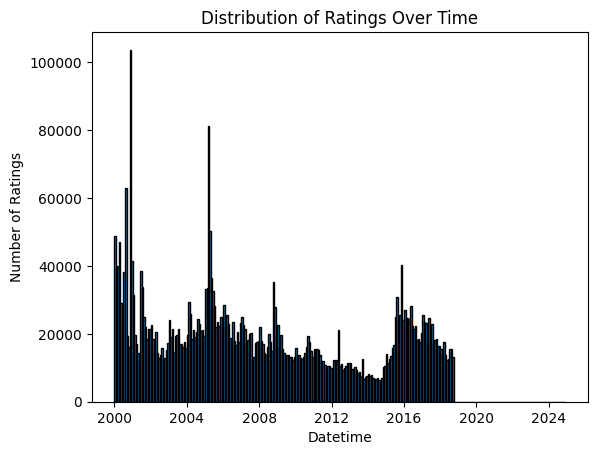

In [4]:
from datetime import datetime

rating_df = pd.read_csv(Config.RATINGS_PATH)

# parse datetime from timestamp
rating_df['datetime'] = pd.to_datetime(rating_df[Config.TIMESTAMP_COL], unit='s')
rating_df = rating_df.sort_values(by='datetime', ascending=False)
display(rating_df.describe())

# distribution of ratings
rating_df = rating_df[rating_df['datetime'] > '2000-01-01']  # filter out ratings before 2000
rating_counts = rating_df['datetime'].value_counts().sort_index()
bins = [datetime(year, month, 1) for year in range(2000, 2025) for month in range(1, 13)]
plt.hist(rating_df['datetime'], bins=bins, edgecolor='black')
plt.title("Distribution of Ratings Over Time")
plt.xlabel("Datetime")
plt.ylabel("Number of Ratings")
plt.show()

# display(f"Min Timestamp: {datetime.fromtimestamp(min_timestamp)} | Max Timestamp: {datetime.fromtimestamp(max_timestamp)}")

## Run preprocessing and dataloader

In [ ]:
# A. Khởi tạo đường dẫn động (Version bằng Timestamp)
dir_path_with_timestamp: Path =  Config.CF_DIR / Config.RUN_TIMESTAMP
os.makedirs(dir_path_with_timestamp, exist_ok=True)

def get_timestamped_path(base_dir: Path, postfix_filename: str) -> Path:
    """
    Tạo đường dẫn tệp với tiền tố timestamp.
    
    Args:
        base_dir (Path): Thư mục cơ sở để lưu tệp.
        postfix_filename (str): Tên tệp gốc.
        
    Returns:
        Path: Đường dẫn tệp mới với tiền tố timestamp.
    """
    return base_dir / f"{Config.RUN_TIMESTAMP}_{postfix_filename}"

model_path: Path = get_timestamped_path(dir_path_with_timestamp, "bmf_model.pt")
metrics_path: Path = get_timestamped_path(dir_path_with_timestamp, "bmf_metrics.json")
history_plot_path: Path = get_timestamped_path(dir_path_with_timestamp, "bmf_history_loss.png")
mapping_path: Path = get_timestamped_path(dir_path_with_timestamp, "mappings.parquet")


# B. Xử lý & Chia tập Dữ liệu
preprocessor = DataPreprocessor(
    csv_path=Config.RATINGS_PATH,
    user_col=Config.USER_COL,
    movie_col=Config.MOVIE_COL,
    rating_col=Config.RATING_COL,
    timestamp_col=Config.TIMESTAMP_COL,
    max_rows=Config.MAX_ROWS_TO_PROCESS,
    chunk_size=Config.CHUNK_SIZE,
    train_ratio=Config.TRAIN_RATIO,
    val_ratio=Config.VAL_RATIO,
    test_ratio=Config.TEST_RATIO,
    num_test_per_user=5,
    num_val_per_user=5,
    parquet_dir=Config.PARQUET_DIR
)
user_mapping, movie_mapping = preprocessor.process_and_split()

# Lưu Mapping
users_df = pd.DataFrame(list(user_mapping.items()), columns=['id', 'idx'])
users_df['type'] = 'user'
movies_df = pd.DataFrame(list(movie_mapping.items()), columns=['id', 'idx'])
movies_df['type'] = 'movie'
pd.concat([users_df, movies_df], ignore_index=True).to_parquet(mapping_path, engine='pyarrow', index=False)

# C. Khởi tạo DataLoader
train_ds = LazyParquetDataset(glob.glob(f"{Config.PARQUET_DIR}/train/*.parquet"), Config.BATCH_SIZE, Config.RATING_COL)
val_ds = LazyParquetDataset(glob.glob(f"{Config.PARQUET_DIR}/val/*.parquet"), Config.BATCH_SIZE, Config.RATING_COL)

train_loader = DataLoader(train_ds, batch_size=None)
val_loader = DataLoader(val_ds, batch_size=None)



## CF Model Training & Evaluation

[INFO] Cấu hình mô hình: {
    "device": "cpu",
    "train_size": 868600,
    "val_size": 65700,
    "epochs": 10,
    "save_model_path": "..\\data\\artifacts\\cf\\20261019_124842_1000000\\20261019_124842_1000000_bmf_model.pt",
    "dropout_rate": 0.2,
    "num_users": 62683,
    "num_movies": 2583,
    "embedding_dim": 64,
    "init_std": 0.010002626106142998
}

[INFO] Bắt đầu huấn luyện...


Epoch 1 [Train]: 100%|██████████| 849/849 [00:43<00:00, 19.68it/s, MSE=1.1041]


[INFO] Validation MSE: 0.9882
Epoch 1/10 | Train MSE: 1.1041 | Val MSE: 0.9882


Epoch 2 [Train]: 100%|██████████| 849/849 [01:03<00:00, 13.35it/s, MSE=0.9516]


[INFO] Validation MSE: 0.9581
Epoch 2/10 | Train MSE: 0.9516 | Val MSE: 0.9581


...

[INFO] Validation MSE: 0.8324
Epoch 8/10 | Train MSE: 0.8289 | Val MSE: 0.8324


Epoch 9 [Train]: 100%|██████████| 849/849 [01:09<00:00, 12.14it/s, MSE=0.7999]


[INFO] Validation MSE: 0.8178
Epoch 9/10 | Train MSE: 0.7999 | Val MSE: 0.8178


Epoch 10 [Train]: 100%|██████████| 849/849 [01:12<00:00, 11.74it/s, MSE=0.7792]


[INFO] Validation MSE: 0.8152
Epoch 10/10 | Train MSE: 0.7792 | Val MSE: 0.8152
[INFO] Huấn luyện hoàn tất sau 10 epochs.
[INFO] Đã lưu mô hình và file metrics thành công tại ..\data\artifacts\cf\20261019_124842_1000000


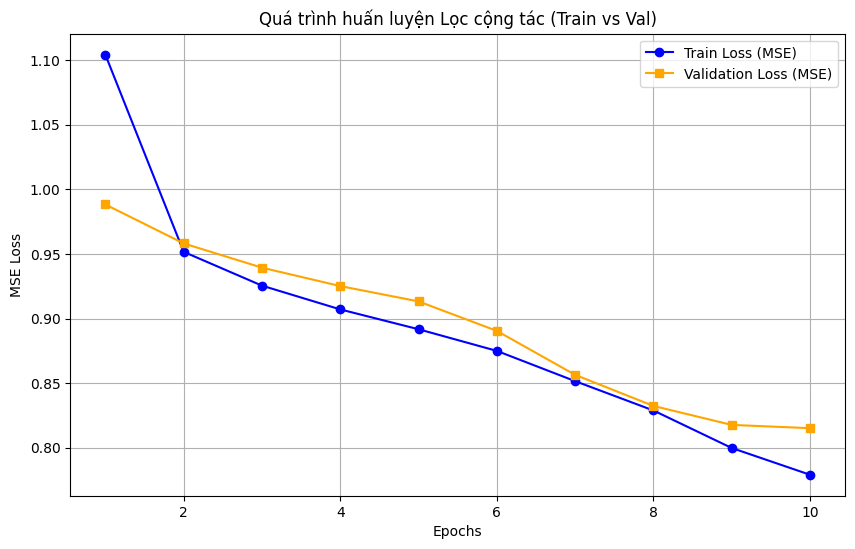

[INFO] Đã lưu biểu đồ thành công tại ..\data\artifacts\cf\20261019_124842_1000000\20261019_124842_1000000_bmf_history_loss.png


In [52]:

# D. Khởi tạo Model & Training
model_pt = CollaborativeFilteringModel(
    len(user_mapping), 
    len(movie_mapping), 
    Config.EMBEDDING_DIM, 
    Config.INIT_STD,
    dropout_param=Config.DROPOUT_RATE if hasattr(Config, 'DROPOUT_RATE') else 0.2
)

trainer = ModelTrainer(
    model=model_pt,
    train_loader=train_loader,
    val_loader=val_loader,
    device=Config.DEVICE,
    learning_rate=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY,
    dropout_rate=Config.DROPOUT_RATE if hasattr(Config, 'DROPOUT_RATE') else 0.2,
    epochs=Config.EPOCHS,
    save_model_path=model_path,
    save_metrics_path=metrics_path
)

history = trainer.train()

# E. Hiển thị Biểu đồ Loss
ResultVisualizer.plot_history(history, history_plot_path)

## Eval CF Model


In [53]:
# plot MSE, RMSE, MAE, R2 Score trên tập Test
def plot_test_evaluation(all_ratings, all_preds):
    plt.figure(figsize=(10, 6))
    plt.scatter(all_ratings, all_preds, alpha=0.5)
    plt.plot([all_ratings.min(), all_ratings.max()], [all_ratings.min(), all_ratings.max()], 'r--', lw=2)
    plt.title('Actual vs Predicted Ratings')
    plt.xlabel('Actual Ratings')
    plt.ylabel('Predicted Ratings')
    plt.grid(True)
    plt.show()


============================== TEST REPORT ==============================
1. Mean Squared Error (MSE)      : 0.8265
2. Root Mean Squared Error (RMSE): 0.9091 (Đoán lệch ~0.91 sao)
3. Mean Absolute Error (MAE)     : 0.6810
4. R-squared (R2 Score)          : 0.2593

[INFO] Đã lưu mô hình và file metrics thành công tại ..\data\artifacts\cf\20261019_124842_1000000


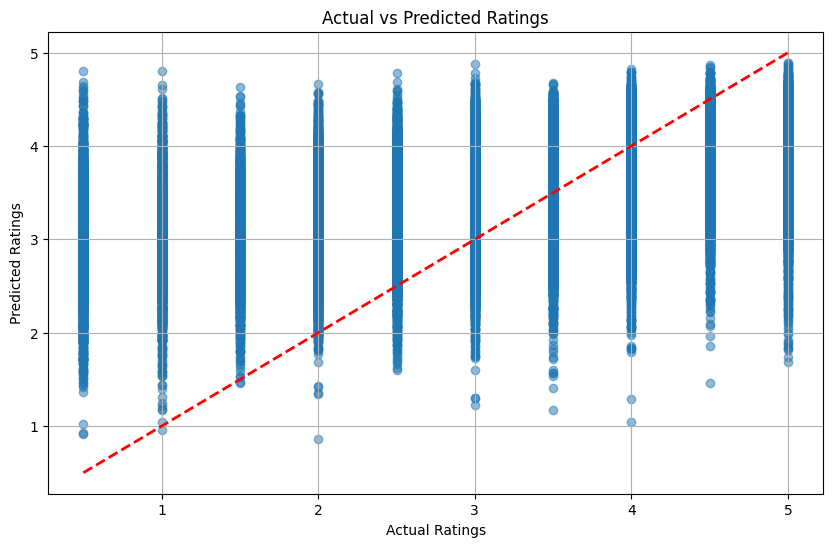

In [54]:
# A. Test Set Evaluation
test_ds = LazyParquetDataset(glob.glob(f"{Config.PARQUET_DIR}/test/*.parquet"), Config.BATCH_SIZE, Config.RATING_COL)
test_loader = DataLoader(test_ds, batch_size=None)

mse, test_metrics, all_preds, all_ratings = trainer.evaluate(test_loader, criterion=nn.MSELoss(), mode="test")
plot_test_evaluation(all_ratings, all_preds)

# B. Thử nghiệm Client với Model vừa train
client = RecommendationClient(model_path, mapping_path, len(user_mapping), len(movie_mapping), Config.EMBEDDING_DIM, Config.INIT_STD, Config.DEVICE)



## ALS model

In [ ]:
# !pip install implicit

In [ ]:
import implicit
from scipy.sparse import csr_matrix

train_df = pd.read_parquet(f"{Config.PARQUET_DIR}/train/data.parquet")
scores = train_df[Config.RATING_COL].values
user_idx = train_df["user_idx"].values
movie_idx = train_df["movie_idx"].values
# 1. Build ma trận sparse: hàng=user, cột=movie, giá trị=score (confidence)
# Đọc số lượng users/movies thực tế từ mapping để set kích thước cứng cho ma trận
mapping_df = pd.read_parquet(mapping_path)
num_users = len(mapping_df[mapping_df["type"] == "user"])
num_movies = len(mapping_df[mapping_df["type"] == "movie"])
matrix = csr_matrix((scores, (user_idx, movie_idx)), shape=(num_users, num_movies))

# 2. Train — KHÔNG có vòng lặp epoch/batch/optimizer.step() thủ công như PyTorch
model_als = implicit.als.AlternatingLeastSquares(
    factors=64,
    regularization=0.01,
    iterations=100,
    random_state=42, 
)
model_als.fit(matrix)   # toàn bộ việc "luân phiên giải" nằm gọn trong 1 dòng này


In [ ]:
# CŨ (SAI): dùng rating làm confidence
# matrix = csr_matrix((scores, (user_idx, movie_idx)))  # scores = 0.5..5

# MỚI (ĐÚNG): 
# Option A: binarize (implicit chuẩn)
#   matrix = (rating >= 3.5).astype(float)   # thích/không
# Option B (khuyến nghị): confidence = 1 + alpha * rating
#   NHƯNG implicit lib KHÔNG nhận confidence riêng — value chính là "độ mạnh"
#   → Binarize + weight bằng rating tương đối
#
# Đơn giản & đúng bản chất:
pos_mask = train_df[Config.RATING_COL] >= 3.5   # positive interactions
matrix = csr_matrix(
    (np.ones(pos_mask.sum()), 
     (train_df["user_idx"].values[pos_mask], train_df["movie_idx"].values[pos_mask])),
    shape=(num_users, num_movies)
)
# Hoặc weight = 1 + rating để vẫn giữ thông tin "thích bao nhiêu"
# (implicit lib coi đây là preference strength)

model_als = implicit.als.AlternatingLeastSquares(
    factors=64, regularization=0.05, alpha=20.0, iterations=30, random_state=42
)
model_als.fit(matrix)

## Test CF model and ALS model

In [ ]:
# 3. Dùng
user_id = 5
recommendations = model_als.recommend(user_id, matrix[user_id], N=10)
user_vectors = model_als.user_factors   # lấy vector nếu cần
movie_vectors = model_als.item_factors

# display(recommendations)
# display(user_vectors)
# display(movie_vectors)

    
for i in range(5):
    user_id = np.random.choice(list(user_idx))
    print(f"User ID: {user_id}")
    print(f"Recommendations by Neural PyTorch Model")
    recommendations = client.recommend(user_idx=user_id, k=Config.TOP_K)
    display(recommendations)
    
    print(f"Recommendations by Implicit")
    recommendations_implicit = model_als.recommend(user_id, matrix[user_id], N=Config.TOP_K)
    display(recommendations_implicit)

## Compare CF model and ALS model

In [ ]:
def recommend_pytorch(model: torch.nn.Module, user_idx: int, idx_to_movie: dict, device=Config.DEVICE, k=10):
    model.eval()
    with torch.no_grad():
        # Lấy trực tiếp kích thước chuẩn từ Embedding layer của model đã train
        num_users = model.user_embedding.num_embeddings
        num_movies = model.movie_embedding.num_embeddings
        
        # Kiểm tra phòng hờ nếu user_idx vượt quá tập train (Cold Start)
        if user_idx >= num_users:
            return np.array([], dtype=np.int32), np.array([], dtype=np.float32)
        
        # Tạo tensor cho user hiện tại và toàn bộ dải index phim hợp lệ [0 -> num_movies - 1]
        u_tensor = torch.tensor([user_idx] * num_movies, dtype=torch.long).to(device)
        m_tensor = torch.arange(num_movies, dtype=torch.long).to(device)
        
        # Forward qua model PyTorch
        predictions = model(u_tensor, m_tensor)
        
        # Lấy top k index có điểm số dự đoán cao nhất
        top_k_tensor = torch.topk(predictions, min(k, num_movies))
        top_k_indices = top_k_tensor.indices.cpu().numpy()
        scores = top_k_tensor.values.cpu().numpy()
        
    return top_k_indices, scores

In [61]:
class Evaluation:
    @staticmethod
    def precision_recall_at_k(recommended_ids, relevant_ids, k):
        relevant_ids = set(relevant_ids)
        hits = len(set(recommended_ids[:k]) & relevant_ids)
        precision = hits / k if k else 0.0
        recall = hits / len(relevant_ids) if relevant_ids else 0.0
        return precision, recall

    @staticmethod
    def f1_at_k(precision, recall):
        return 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    @staticmethod
    def hit_rate_at_k(recommended_ids, relevant_ids, k):
        return float(bool(set(recommended_ids[:k]) & set(relevant_ids)))

    @staticmethod
    def ndcg_at_k(recommended_ids, relevant_ids, k):
        relevant_ids = set(relevant_ids)
        dcg = sum(
            1 / np.log2(rank + 2)
            for rank, item in enumerate(recommended_ids[:k])
            if item in relevant_ids
        )
        ideal_hits = min(len(relevant_ids), k)
        idcg = sum(1 / np.log2(rank + 2) for rank in range(ideal_hits))
        return dcg / idcg if idcg else 0.0

    @staticmethod
    def mean_reciprocal_rank(recommended_ids, relevant_ids, k):
        relevant_ids = set(relevant_ids)
        for rank, item in enumerate(recommended_ids[:k]):
            if item in relevant_ids:
                return 1 / (rank + 1)
        return 0.0

    @staticmethod
    def mean_average_precision_at_k(recommended_ids, relevant_ids, k):
        relevant_ids = set(relevant_ids)
        if not relevant_ids:
            return 0.0
        hits, precision_sum = 0, 0.0
        for rank, item in enumerate(recommended_ids[:k]):
            if item in relevant_ids:
                hits += 1
                precision_sum += hits / (rank + 1)
        # MAP@K: chuẩn hóa theo số relevant có thể tìm thấy trong top-K.
        return precision_sum / min(len(relevant_ids), k) if k and relevant_ids else 0.0

    @staticmethod
    def _rank_candidates(model, user_id, num_movies, seen_ids, model_type, device):
        candidates = np.array([i for i in range(num_movies) if i not in seen_ids], dtype=np.int64)
        if not len(candidates):
            return candidates

        if model_type == "bmf":
            model.eval()
            with torch.no_grad():
                users = torch.full((len(candidates),), int(user_id), dtype=torch.long, device=device)
                movies = torch.as_tensor(candidates, dtype=torch.long, device=device)
                scores = model(users, movies).detach().cpu().numpy()
        elif model_type == "als":
            # Chấm điểm trên cùng candidate set; không dùng implicit.recommend để tránh
            # khác biệt ngầm về lọc item đã tương tác giữa hai mô hình.
            scores = model.user_factors[user_id] @ model.item_factors[candidates].T
        else:
            raise ValueError("model_type phải là 'bmf' hoặc 'als'")

        order = np.argsort(-scores)[:]
        return candidates[order]

    @staticmethod
    def evaluate_all(
        model, train_df, test_df, num_movies, k=10, model_type="bmf",
        relevance_threshold=4.0, device=Config.DEVICE
    ):
        # Ground truth chỉ gồm rating được định nghĩa là positive/relevant.
        relevant_test = test_df[test_df[Config.RATING_COL] >= relevance_threshold]
        if relevant_test.empty:
            raise ValueError(
                f"Không có rating >= {relevance_threshold}; hãy kiểm tra ngưỡng relevant."
            )

        seen_by_user = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
        rows = []
        for user_id, group in relevant_test.groupby("user_idx"):
            relevant_ids = set(group["movie_idx"].astype(int))
            seen_ids = seen_by_user.get(int(user_id), set())
            ranked = Evaluation._rank_candidates(
                model, int(user_id), num_movies, seen_ids, model_type, device
            )[:k]

            precision, recall = Evaluation.precision_recall_at_k(ranked, relevant_ids, k)
            rows.append({
                "user_id": int(user_id),
                "precision@k": precision,
                "recall@k": recall,
                "f1@k": Evaluation.f1_at_k(precision, recall),
                "hit_rate@k": Evaluation.hit_rate_at_k(ranked, relevant_ids, k),
                "ndcg@k": Evaluation.ndcg_at_k(ranked, relevant_ids, k),
                "mrr@k": Evaluation.mean_reciprocal_rank(ranked, relevant_ids, k),
                "map@k": Evaluation.mean_average_precision_at_k(ranked, relevant_ids, k),
            })

        metrics = ["precision@k", "recall@k", "f1@k", "hit_rate@k",
                   "ndcg@k", "mrr@k", "map@k"]
        result = {"k": k, "model_type": model_type,
                  "relevance_threshold": relevance_threshold,
                  "evaluated_users": len(rows)}
        result.update({metric: float(np.mean([row[metric] for row in rows])) for metric in metrics})
        return result


In [62]:
test_df = pd.read_parquet(Config.PARQUET_DIR / "test" / "data.parquet")
display(test_df.head(10))
display(test_df.info())

,userId,movieId,rating,timestamp,user_idx,movie_idx
0,5948,5319,4.0,1452646854,2,479
1,5948,85414,3.0,1471248263,2,225
2,5948,8665,3.5,1482714795,2,64
3,5948,1689,2.5,1482715012,2,250
4,5948,1967,3.5,1512170962,2,305
5,169639,85414,4.5,1536199324,5,225
6,169639,2722,4.0,1536692233,5,0
7,169639,1911,2.5,1536692252,5,264
8,169639,122924,5.0,1537235673,5,1712
9,169639,122906,5.0,1537295990,5,1975


<class 'pandas.DataFrame'>
RangeIndex: 65700 entries, 0 to 65699
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userId     65700 non-null  int64  
 1   movieId    65700 non-null  int64  
 2   rating     65700 non-null  float64
 3   timestamp  65700 non-null  int64  
 4   user_idx   65700 non-null  int64  
 5   movie_idx  65700 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 3.0 MB


None

In [63]:
train_df = pd.read_parquet(Config.PARQUET_DIR / "train" / "data.parquet")
test_df = pd.read_parquet(Config.PARQUET_DIR / "test" / "data.parquet")
num_movies = len(movie_mapping)

In [64]:


eval_pt = Evaluation.evaluate_all(
    model=model_pt,
    train_df=train_df,
    test_df=test_df,
    num_movies=num_movies,
    k=Config.TOP_K,
    model_type="bmf",
    relevance_threshold=Config.RELEVANCE_THRESHOLD,
    device=Config.DEVICE,
)
display(eval_pt)


{'k': 10,
 'model_type': 'bmf',
 'relevance_threshold': 4.0,
 'evaluated_users': 11187,
 'precision@k': 0.03624743005273979,
 'recall@k': 0.12361073865498645,
 'f1@k': 0.053912134764910316,
 'hit_rate@k': 0.27800125145257887,
 'ndcg@k': 0.08931467662691538,
 'mrr@k': 0.11989316539464033,
 'map@k': 0.05354539329711404}

In [65]:
eval_als = Evaluation.evaluate_all(
    model=model_als,
    train_df=train_df,
    test_df=test_df,
    num_movies=num_movies,
    k=Config.TOP_K,
    model_type="als",
    relevance_threshold=Config.RELEVANCE_THRESHOLD,
    device=Config.DEVICE,
)
display(eval_als)


{'k': 10,
 'model_type': 'als',
 'relevance_threshold': 4.0,
 'evaluated_users': 11187,
 'precision@k': 0.037659783677482794,
 'recall@k': 0.13334972140281875,
 'f1@k': 0.056411435172497124,
 'hit_rate@k': 0.31009207115401805,
 'ndcg@k': 0.09053790302474388,
 'mrr@k': 0.11955720997018932,
 'map@k': 0.05104691031682181}

In [66]:
evaluation_results = [
    {"model_type": "bmf", **eval_pt},
    {"model_type": "als", **eval_als},
]


In [67]:
df_eval_results = pd.DataFrame(evaluation_results)
display(df_eval_results)

eval_results_path: Path = dir_path_with_timestamp / f"{Config.RUN_TIMESTAMP}_bmf_als_evaluation_results.csv"
df_eval_results.to_csv(eval_results_path, index=False)
print(f"[INFO] Evaluation results saved to: {eval_results_path}")


,model_type,k,relevance_threshold,evaluated_users,precision@k,recall@k,f1@k,hit_rate@k,ndcg@k,mrr@k,map@k
0,bmf,10,4.0,11187,0.036247,0.123611,0.053912,0.278001,0.089315,0.119893,0.053545
1,als,10,4.0,11187,0.037660,0.133350,0.056411,0.310092,0.090538,0.119557,0.051047


[INFO] Evaluation results saved to: ..\data\artifacts\cf\20261019_124842_1000000\20261019_124842_1000000_bmf_als_evaluation_results.csv


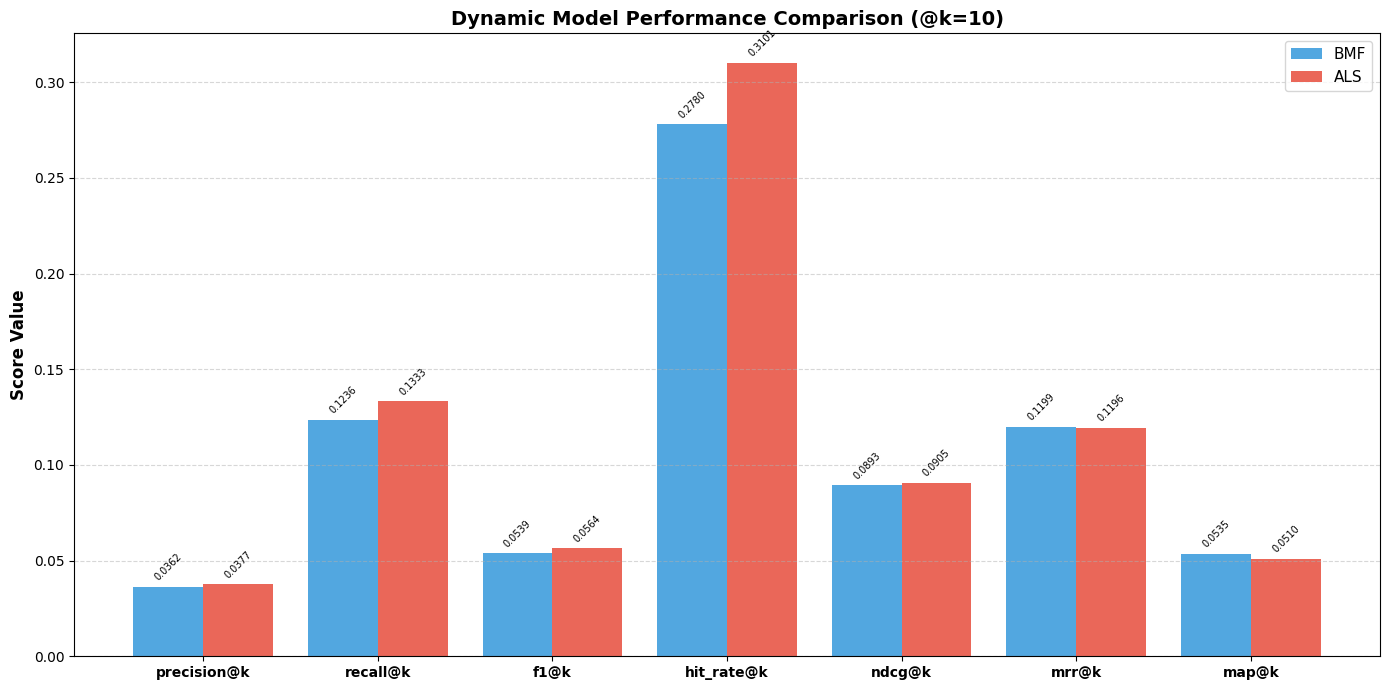

In [68]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Đọc dữ liệu từ file CSV đánh giá (thay 'evaluation_results.csv' bằng file thực tế của bạn)
df = pd.read_csv(eval_results_path)

# Tự động lấy danh sách metrics và các model từ file
metrics = [col for col in df.columns if col not in ['model_type', 'k', 'evaluated_users', 'relevance_threshold']]
models = df['model_type'].tolist()

x = np.arange(len(metrics))
num_models = len(models)
total_width = 0.8  # Tổng bề ngang cho một cụm cột
width = total_width / num_models  # Tự chia bề ngang theo số lượng model

# Khởi tạo biểu đồ
fig, ax = plt.subplots(figsize=(14, 7))
rects_list = []
colors = ['#3498db', '#e74c3c', '#2ecc71', '#9b59b6', '#f1c40f', '#e67e22']

# 2. Vòng lặp vẽ cột động cho từng model
for i, model in enumerate(models):
  scores = df[df['model_type'] == model][metrics].values[0]
  offset = (i - num_models / 2 + 0.5) * width
  color = colors[i % len(colors)]

  rects = ax.bar(
      x + offset, scores, width, label=model.upper(), color=color, alpha=0.85
  )
  rects_list.append(rects)

# 3. Cấu hình giao diện biểu đồ
ax.set_ylabel('Score Value', fontsize=12, fontweight='bold')
ax.set_title(
    'Dynamic Model Performance Comparison (@k=10)',
    fontsize=14,
    fontweight='bold',
)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=10, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)


# 4. Hàm hiển thị giá trị chính xác trên mỗi cột
def autolabel(rects):
  for rect in rects:
    height = rect.get_height()
    if height > 0:
      ax.annotate(
          f'{height:.4f}',
          xy=(rect.get_x() + rect.get_width() / 2, height),
          xytext=(0, 3),
          textcoords='offset points',
          ha='center',
          va='bottom',
          fontsize=7,
          rotation=45,
      )


for rects in rects_list:
  autolabel(rects)

plt.tight_layout()
plt.savefig('dynamic_model_comparison.png', dpi=300)
plt.show()

# save the figure
fig.savefig(dir_path_with_timestamp / f"{Config.RUN_TIMESTAMP}_bmf_als_evaluation_results.png")